# Módulo 4 — Extracción de Entidades (NER) y Grafo de Conocimiento
**Pungo Academy · NLP para Mantenimiento Industrial (Nivel Avanzado)**

## Objetivo
Construir un extractor híbrido **Regex + LLM (GPT NER)** capaz de estructurar automáticamente equipos, componentes, modos de falla, mediciones físicas, acciones correctivas y **materiales/repuestos** desde ambas columnas narrativas (`descripcion_problema` + `descripcion_trabajo`), materializando un **Grafo de Conocimiento `Equipo → Falla`**.

## Contenido
1. Taxonomía de entidades industriales (6 tipos clave)
2. Extracción ultrarrápida y determinística con Regex sobre las 3,030 OTs
3. Extracción semántica con `gpt-4o-mini` combinando problema + trabajo realizado
4. Construcción y visualización NetworkX del Grafo de Conocimiento `Equipo → Falla`
5. Ranking Pareto de componentes críticos y consumo de repuestos

In [1]:
import importlib.util, subprocess, sys
for pkg in ("openai", "networkx"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import json, re, time
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Paleta corporativa oficial Pungo Tech 2027
PUNGO_NAVY = "#0D202B"
PUNGO_BLUE = "#007297"
PUNGO_LIME = "#8EC14B"
PUNGO_AMBER = "#E8820C"
PUNGO_RED = "#C0392B"
PUNGO_SLATE = "#475569"
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.titleweight"] = "bold"
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# Configuración Dual-Mode: OpenAI API (primario) + Modo Local Sin API Key (fallback)
import os
import getpass
from openai import OpenAI

api_key = os.environ.get("OPENAI_API_KEY", "").strip()
if not api_key:
    try:
        api_key = getpass.getpass(
            "Ingresa tu OpenAI API Key (o presiona Enter para Modo Local sin costo): "
        ).strip()
    except Exception:
        api_key = ""

USE_OPENAI = bool(api_key)
client = OpenAI(api_key=api_key) if USE_OPENAI else None
print(
    f"Modo activo: {'OpenAI API Live (gpt-4o-mini + text-embedding-3-small)' if USE_OPENAI else 'Modo Local Determinístico (TF-IDF + Reglas)'}"
)

Modo activo: OpenAI API Live (gpt-4o-mini + text-embedding-3-small)


In [3]:
df = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_nlp/curso_nlp_work_orders.csv")
df["texto_completo"] = (
    "Problema: " + df["descripcion_problema"].fillna("")
    + "\nTrabajo realizado: " + df["descripcion_trabajo"].fillna("")
)
print(f"Total OTs: {len(df):,}")
print("\nEjemplo de narrativa combinada (Problema + Trabajo):")
print(df["texto_completo"].iloc[0])

Total OTs: 3,030

Ejemplo de narrativa combinada (Problema + Trabajo):
Problema: Válvula de control V-102 no responde a señal del controlador. Posicionador descalibrado.
Trabajo realizado: Se reemplazó transmisor Separador de prueba. Nuevo: Rosemount modelo EJA530. Configurado y verificado contra instrumento local.


## 1. Extracción Determinística con Expresiones Regulares (Regex)
Para patrones estructurados como tags de activos (`P-101A`, `XV-1001`) y magnitudes con unidades (`93°C`, `4.5 mm/s`, `350 psi`), **Regex procesa las 3,030 OTs en milisegundos con cero costo de API**.

In [4]:
PATTERNS = {
    "EQUIPO_TAG": r"\b([A-Z]{1,3}-\d{2,4}[A-B]?)\b",
    "INSTRUMENTO_TAG": r"\b([A-Z]{2,3}-\d{4})\b",
    "MEDICION_TEMP": r"(\d+\.?\d*)\s*°?\s*[Cc]\b",
    "MEDICION_PRESION": r"(\d+\.?\d*)\s*(?:psi|bar|kPa)\b",
    "MEDICION_VIBRACION": r"(\d+\.?\d*)\s*mm/s\b",
    "MEDICION_PORCENTAJE": r"(\d+\.?\d*)\s*%",
    "MEDICION_ESPESOR": r"(\d+\.?\d*)\s*mm\b",
    "OT_REFERENCIA": r"(OT-\d{4}-\d{4,5})",
}

def extraer_con_regex(texto: str) -> dict:
    if pd.isna(texto):
        return {}
    entidades = {}
    for tipo, pattern in PATTERNS.items():
        matches = re.findall(pattern, str(texto))
        if matches:
            if isinstance(matches[0], tuple):
                matches = [m[0] for m in matches]
            entidades[tipo] = sorted(set(matches))
    return entidades

df["entidades_regex"] = df["texto_completo"].apply(extraer_con_regex)
tags_count = df["entidades_regex"].apply(lambda x: len(x.get("EQUIPO_TAG", []) + x.get("INSTRUMENTO_TAG", [])))
meds_count = df["entidades_regex"].apply(lambda x: sum(len(v) for k, v in x.items() if k.startswith("MEDICION")))

print(f"OTs con al menos un tag de equipo/instrumento : {(tags_count > 0).sum():,} ({(tags_count > 0).mean():.1%})")
print(f"OTs con al menos una medición cuantitativa    : {(meds_count > 0).sum():,} ({(meds_count > 0).mean():.1%})")

OTs con al menos un tag de equipo/instrumento : 2,700 (89.1%)
OTs con al menos una medición cuantitativa    : 1,517 (50.1%)


## 2. Extracción Semántica con OpenAI (`descripcion_problema` + `descripcion_trabajo`)
> **Mejora clave:** Si solo enviamos `descripcion_problema`, casi nunca aparecen repuestos ni materiales instalados. Al pasar **problema + trabajo realizado**, el modelo extrae con precisión componentes cambiados, marcas/modelos (`Rosemount`, `Yokogawa`, `PTFE`) y acciones ejecutadas.

In [5]:
SYSTEM_PROMPT_NER = """Eres un ingeniero de confiabilidad experto en mantenimiento industrial.
Extrae entidades técnicas tanto del problema reportado como del trabajo realizado.
Responde SOLO con JSON válido:
{
  "equipos": ["tags y nombres de equipos"],
  "partes": ["componentes específicos: sello mecánico, rodamiento, impeller, posicionador, brida, etc."],
  "fallas": ["condiciones anormales o modos de falla"],
  "mediciones": [{"valor": "número", "unidad": "unidad", "parametro": "variable"}],
  "acciones": ["acciones de diagnóstico o reparación"],
  "materiales": ["repuestos, marcas/modelos, juntas PTFE, aceite, empaquetaduras, etc."]
}
Si una categoría no aparece, devuelve []."""

PARTES_KW = ["sello mecánico", "rodamiento", "impeller", "transmisor", "posicionador", "brida", "junta", "tubing", "motor", "acople", "empaque", "válvula"]
MAT_KW = ["rosemount", "yokogawa", "ptfe", "skf", "aceite sintético", "recubrimiento antierosión", "empaquetadura", "cartucho", "junta de brida"]

def extraer_entidades_gpt(texto: str) -> dict:
    if USE_OPENAI:
        try:
            resp = client.chat.completions.create(
                model="gpt-4o-mini",
                messages=[
                    {"role": "system", "content": SYSTEM_PROMPT_NER},
                    {"role": "user", "content": texto},
                ],
                temperature=0,
                response_format={"type": "json_object"},
            )
            return json.loads(resp.choices[0].message.content)
        except Exception as exc:
            print(f"Fallback NER por error API: {exc}")
    tl = texto.lower()
    rx = extraer_con_regex(texto)
    return {
        "equipos": rx.get("EQUIPO_TAG", []) + rx.get("INSTRUMENTO_TAG", []),
        "partes": [p for p in PARTES_KW if p in tl],
        "fallas": [f for f in ["fuga", "vibración", "corrosión", "desgaste", "descalibrado", "erosión", "sobrecalentamiento"] if f in tl],
        "mediciones": [],
        "acciones": [a for a in ["reemplazó", "calibración", "verificó", "alineación", "reparación"] if a in tl],
        "materiales": [m for m in MAT_KW if m in tl],
    }

for _, row in df.sample(2, random_state=99).iterrows():
    ent = extraer_entidades_gpt(row["texto_completo"])
    print(f"\n[{row['wo_id']}] {row['equipo_tag']}")
    print(json.dumps(ent, ensure_ascii=False, indent=2))


[OT-2024-02844] FT-1503
{
  "equipos": [
    "FT-1503"
  ],
  "partes": [
    "impeller"
  ],
  "fallas": [
    "juego excesivo en tubing de impulso"
  ],
  "mediciones": [
    {
      "valor": 0.86,
      "unidad": "mm",
      "parametro": "holgura"
    }
  ],
  "acciones": [
    "reemplazo de impeller",
    "verificación de balance dinámico"
  ],
  "materiales": [
    "nuevo impeller con recubrimiento antierosión"
  ]
}



[OT-2024-02319] V-101
{
  "equipos": [
    "Compresor V101"
  ],
  "partes": [
    "impeller"
  ],
  "fallas": [
    "caída de eficiencia",
    "erosión en etapas"
  ],
  "mediciones": [
    {
      "valor": 40,
      "unidad": "%",
      "parametro": "flujo"
    }
  ],
  "acciones": [
    "reemplazo de impeller",
    "verificación de balance dinámico"
  ],
  "materiales": [
    "nuevo impeller con recubrimiento antierosión"
  ]
}


In [6]:
sample = df.sample(50, random_state=42)
print("Extrayendo entidades de 50 OTs (problema + trabajo)...")

all_entities = []
for i, (_, row) in enumerate(sample.iterrows()):
    ent = extraer_entidades_gpt(row["texto_completo"])
    if ent:
        ent["wo_id"] = row["wo_id"]
        ent["equipo_tag_cmms"] = row["equipo_tag"]
        ent["modo_falla_real"] = row["modo_falla"]
        all_entities.append(ent)
    if (i + 1) % 25 == 0:
        print(f"  Progreso NER: {i + 1}/50")
    if USE_OPENAI:
        time.sleep(0.05)

con_materiales = sum(1 for e in all_entities if e.get("materiales"))
con_partes = sum(1 for e in all_entities if e.get("partes"))
print(f"\nCompletado: {len(all_entities)} OTs | Con partes: {con_partes}/50 | Con materiales/repuestos: {con_materiales}/50")

Extrayendo entidades de 50 OTs (problema + trabajo)...


  Progreso NER: 25/50


  Progreso NER: 50/50

Completado: 50 OTs | Con partes: 41/50 | Con materiales/repuestos: 18/50


## 3. Grafo de Conocimiento `Equipo → Modo de Falla`
Transformamos las entidades extraídas en relaciones dirigidas para detectar cuellos de botella crónicos por activo.

GRAFO DE CONOCIMIENTO (Top 12 Equipos)
  AT-1505        → acumulación de sólidos (1), nivel de interface crudo/agu (1)
  C-101          → alarma de vibración hh (1)
  C-102          → vibracion_excesiva (1)
  C-103          → desbalance de corriente entr (1)
  CR-001         → no cierra completamente (1)
  E-101          → punto caliente (1), riesgo de falla (1)
  E-102          → falla de comunicación (1), sin respuesta en red modbus (1), punto caliente (1)
  E-201          → temperatura de operación ele (1), caída de presión de descarga (1), desgaste de impeller (1)
  FT-1503        → caída de presión de descarga (1), posible desgaste de impeller (1), fuga incipiente (1)
  G-101          → emisión fugitiva (1), fouling severo (1), eficiencia térmica reducida (1)
  GAS-001        → temperatura de operación ele (1)
  LN-GAS-001     → desgaste_mecanico (1)


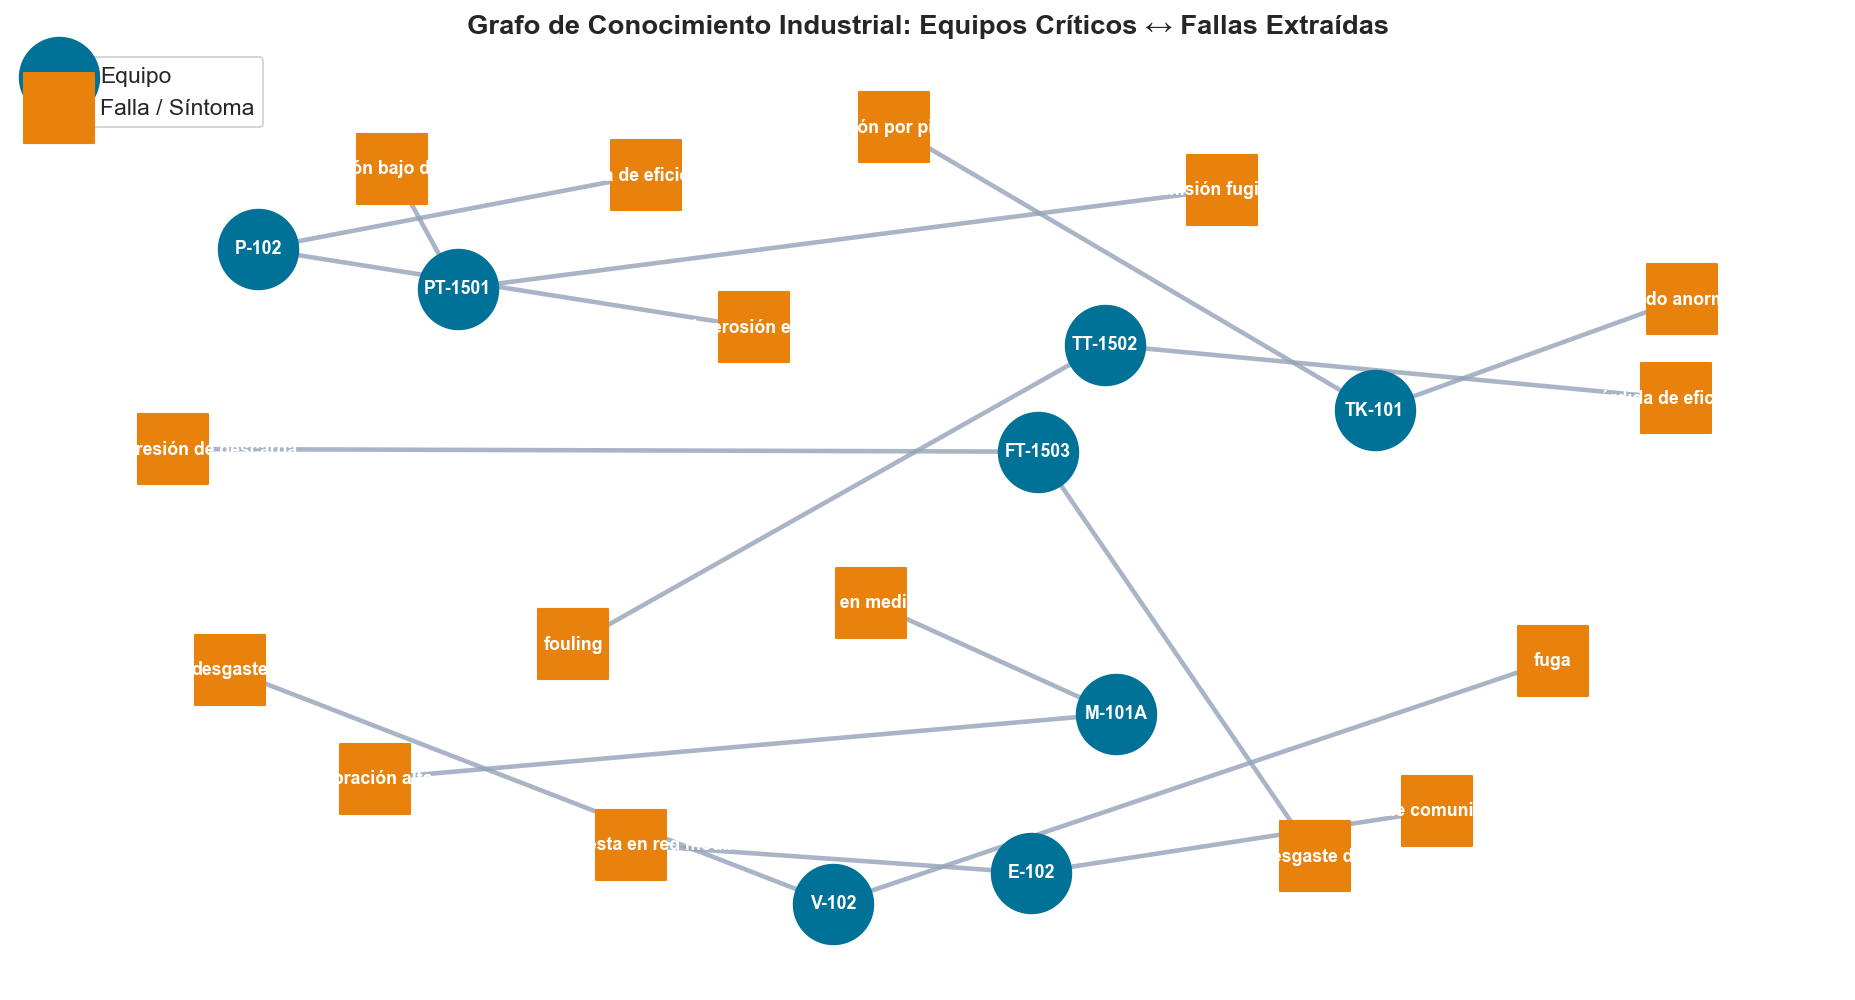

In [7]:
grafo = defaultdict(Counter)
for ent in all_entities:
    rx_tags = extraer_con_regex(" ".join(str(x) for x in ent.get("equipos", []))).get("EQUIPO_TAG", [])
    tags = rx_tags if rx_tags else [ent["equipo_tag_cmms"]]
    fallas = ent.get("fallas", []) or [ent["modo_falla_real"]]
    for eq in tags:
        for f in fallas:
            grafo[eq][str(f).lower()[:28]] += 1

print("GRAFO DE CONOCIMIENTO (Top 12 Equipos)")
print("=" * 64)
for eq in sorted(grafo.keys())[:12]:
    rel = ", ".join(f"{f} ({c})" for f, c in grafo[eq].most_common(3))
    print(f"  {eq:14s} → {rel}")

# Subgrafo NetworkX de los 8 equipos más conectados
G = nx.Graph()
top_eqs = sorted(grafo.keys(), key=lambda k: sum(grafo[k].values()), reverse=True)[:8]
for eq in top_eqs:
    G.add_node(eq, kind="equipo")
    for falla, w in grafo[eq].most_common(2):
        G.add_node(falla, kind="falla")
        G.add_edge(eq, falla, weight=w)

fig, ax = plt.subplots(figsize=(12.5, 6.8))
pos = nx.spring_layout(G, seed=42, k=1.25)
eq_nodes = [n for n, d in G.nodes(data=True) if d.get("kind") == "equipo"]
fa_nodes = [n for n, d in G.nodes(data=True) if d.get("kind") == "falla"]

nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#94A3B8", width=[1.2 + G[u][v]["weight"] for u, v in G.edges()], alpha=0.8)
nx.draw_networkx_nodes(G, pos, nodelist=eq_nodes, node_color=PUNGO_BLUE, node_size=1450, ax=ax, label="Equipo")
nx.draw_networkx_nodes(G, pos, nodelist=fa_nodes, node_color=PUNGO_AMBER, node_size=1100, node_shape="s", ax=ax, label="Falla / Síntoma")
nx.draw_networkx_labels(G, pos, font_size=8.5, font_weight="bold", font_color="white", ax=ax)
ax.set_title("Grafo de Conocimiento Industrial: Equipos Críticos ↔ Fallas Extraídas")
ax.legend(loc="upper left", frameon=True)
ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Ranking de Partes Falladas y Repuestos Consumidos

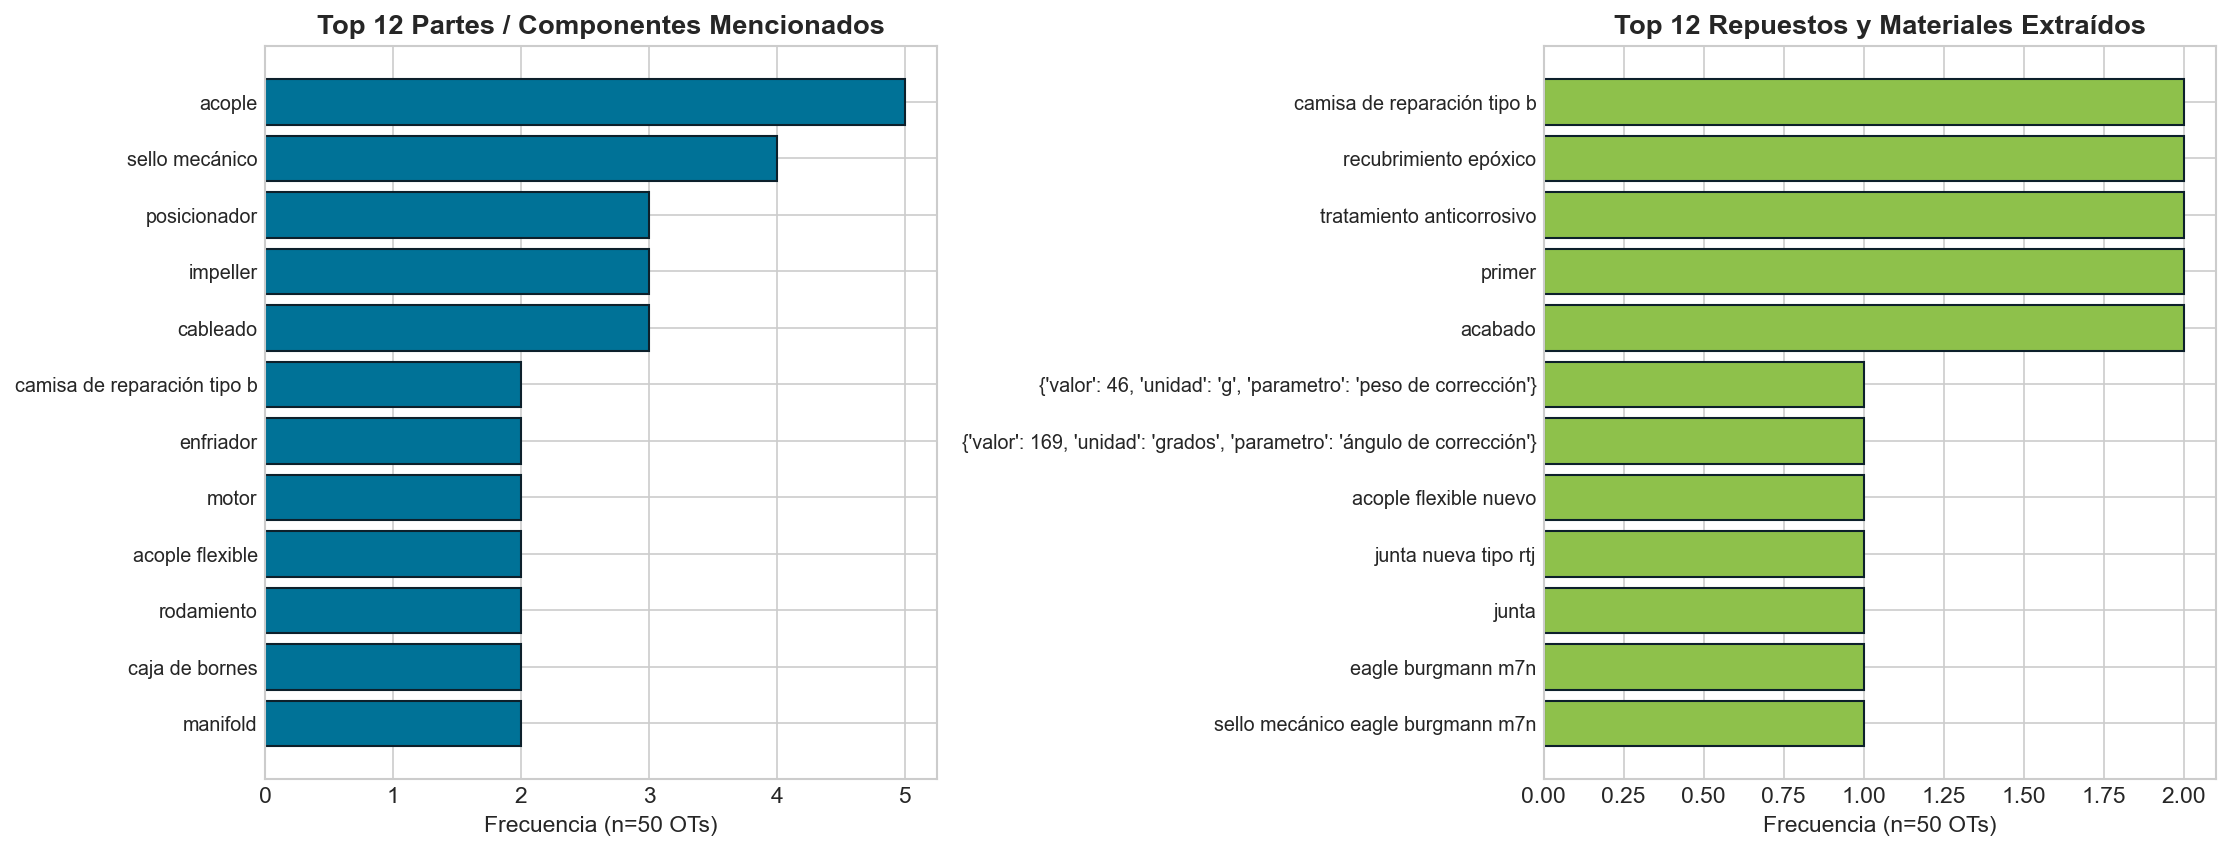

In [8]:
all_parts = [str(p).lower().strip() for ent in all_entities for p in ent.get("partes", [])]
all_mats = [str(m).lower().strip() for ent in all_entities for m in ent.get("materiales", [])]

parts_top = Counter(all_parts).most_common(12)
mats_top = Counter(all_mats).most_common(12)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
if parts_top:
    p_lbl, p_val = zip(*parts_top)
    axes[0].barh(range(len(p_lbl) - 1, -1, -1), p_val, color=PUNGO_BLUE, edgecolor=PUNGO_NAVY)
    axes[0].set_yticks(range(len(p_lbl) - 1, -1, -1))
    axes[0].set_yticklabels(p_lbl, fontsize=9.5)
    axes[0].set_title("Top 12 Partes / Componentes Mencionados")
    axes[0].set_xlabel("Frecuencia (n=50 OTs)")

if mats_top:
    m_lbl, m_val = zip(*mats_top)
    axes[1].barh(range(len(m_lbl) - 1, -1, -1), m_val, color=PUNGO_LIME, edgecolor=PUNGO_NAVY)
    axes[1].set_yticks(range(len(m_lbl) - 1, -1, -1))
    axes[1].set_yticklabels(m_lbl, fontsize=9.5)
    axes[1].set_title("Top 12 Repuestos y Materiales Extraídos")
    axes[1].set_xlabel("Frecuencia (n=50 OTs)")

plt.tight_layout()
plt.show()

## 5. Conclusiones del Módulo 4
- Combinar **Regex** (tags y mediciones exactas sobre el 100% del historial) con **GPT NER** (componentes, acciones y repuestos) equilibra velocidad y profundidad semántica.
- Incluir `descripcion_trabajo` resuelve la ceguera de inventario y permite enlazar fallas con repuestos reales (`Rosemount`, `PTFE`, `sellos mecánicos`).